# Netflix: One Page, One Finding — Data Analysis Notebook

**Research question:** *What kind of company is Netflix now, and when did it change?*  
**Dataset:** [Netflix Movies and TV Shows — Kaggle (shivamb)](https://www.kaggle.com/datasets/shivamb/netflix-shows)

> **Scope of the evidence.** This dataset is a historical catalogue snapshot with additions dated through **25 September 2021**. Here, “now” can only mean **the most recent period observable in this dataset**, not Netflix in 2026. We investigate *catalogue entries and their metadata*, not viewing behavior, production spending, or Netflix's complete business strategy.

**Workflow:** 1. Load and profile → 2. State three hypotheses → 3. Clean with justification → 4. Explore → 5. Test each hypothesis → 6. Investigate three data problems → 7. Conclusion and limitations.

**By:** Isela Zhuga, Nigel Xherimeja, Sara Petro

## 1. Load and profile

Two commands — `pd.read_csv` and a profile table — then a short paragraph on what the columns mean.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

DATA_FILE = next(
    (p for p in [
        Path('/content/netflix_titles.csv'),   
        Path('netflix_titles.csv'),            
    ] if p.exists()),
    None,
)
if DATA_FILE is None:
    raise FileNotFoundError(
        'Upload netflix_titles.csv to the Colab Files panel, then run again.'
    )
print(f'Reading: {DATA_FILE}')

FIGURES = Path('figures')
FIGURES.mkdir(exist_ok=True)

pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 70)
plt.rcParams.update({
    'figure.dpi': 110,
    'savefig.dpi': 200,
    'font.size': 11,
    'axes.titlesize': 14,
    'axes.labelsize': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': False,
})

BLUE = '#17446A'
ORANGE = '#DF805B'
GRAY = '#667788'

raw = pd.read_csv(DATA_FILE)
print(f'Original dataset shape: {raw.shape[0]:,} rows × {raw.shape[1]} columns')
display(raw.head(3))

Reading: /content/netflix_titles.csv
Original dataset shape: 8,807 rows × 12 columns


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmmaker Kirsten Johnson..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thabang Molaba, Dillon Win...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town teen sets out to prov..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabiha Akkari, Sofia Les...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Action & Adventure","To protect his family from a powerful drug lord, skilled thief Meh..."


In [3]:
profile = pd.DataFrame({
    'data_type': raw.dtypes.astype(str),
    'missing': raw.isna().sum(),
    'missing_pct': (100 * raw.isna().mean()).round(1),
    'unique_nonmissing': raw.nunique(dropna=True),
})
display(profile)
print('Duplicate full rows:', raw.duplicated().sum())
print('Duplicate show IDs:', raw['show_id'].duplicated().sum())

,data_type,missing,missing_pct,unique_nonmissing
show_id,object,0,0.0,8807
type,object,0,0.0,2
title,object,0,0.0,8807
director,object,2634,29.9,4528
cast,object,825,9.4,7692
country,object,831,9.4,748
date_added,object,10,0.1,1767
release_year,int64,0,0.0,74
rating,object,4,0.0,17
duration,object,3,0.0,220


Duplicate full rows: 0
Duplicate show IDs: 0


### What the columns mean

| Column | Interpretation |
|---|---|
| `show_id` | Identifier assigned to a catalogue entry |
| `type` | Movie or TV Show |
| `title` | Listed name of the title |
| `director`, `cast` | Credits; may be missing |
| `country` | Listed production country/countries; may be missing or multi-valued |
| `date_added` | Date the title was added to Netflix, **not** necessarily its release date |
| `release_year` | Release year associated with the title |
| `rating` | Listed content rating; some records have quality issues |
| `duration` | Running time for a movie or season count for a show |
| `listed_in` | Comma-separated catalogue labels, often more than one per title |
| `description` | Short catalogue synopsis |

**Initial profile:** Directors, cast and country contain substantial missing data. Country is crucial to H2 and must not be silently filled with “United States” or “Unknown” and counted as a genuine country. The dates must be parsed before doing time-based analysis.

## 2. Three hypotheses — documented before the exploration


Our goal is to understand how Netflix's catalogue has changed over time. We will explore three hypotheses using pandas and data visualizations.

### H1 — Movies vs. TV Shows

**Hypothesis:** The percentage of TV Shows added to Netflix has increased over time.

We will compare Movies and TV Shows to see how their proportions have changed and identify the year with the biggest change.

### H2 — International Content

**Hypothesis:** Netflix has increased the percentage of content from countries outside the United States.

We will compare the percentage of titles produced exclusively outside the US across different periods. Titles with missing country information will be excluded from this comparison.

### H3 — Genre Changes

**Hypothesis:** The types of content added to Netflix have changed over time.

We will explore the most common movie genres and compare their percentages across different periods to see which genres became more or less common.

### Time Period

We will mainly compare **2017–2018** with **2019–2020**, since these periods contain enough data for a meaningful comparison.  Additions before 2017 are much more sparsely represented; 2021 ends in September, so a full-year comparison would be misleading. The two fixed two-year windows provide substantial and comparable groups.

We will use `date_added` to identify when each title was added to Netflix, rather than `release_year`, which represents when the title was originally released.


## 3. Cleaning — every decision and its reason

| Step | Decision | Reason |
|---|---|---|
| 1 | Keep the original `raw` DataFrame unchanged; work in `df` | Preserve traceability and allow checks against source rows |
| 2 | Trim whitespace in key string columns | Avoid mismatched labels and unreliable date parsing |
| 3 | Parse `date_added`; create `added_year` | `release_year` cannot substitute for year added to Netflix |
| 4 | Split comma-separated `country` and `listed_in` into lists | Country co-productions and multiple tags must be represented correctly |
| 5 | Verify uniqueness of `show_id` rather than blindly dropping rows | Duplicate removal should occur only with evidence |
| 6 | Keep null countries as unknown | Guessing countries would bias internationalization rates |
| 7 | Filter to 2017–2020 **for the main comparisons only** | Exclude sparse early years and incomplete 2021; retain full data for profiling and quality checks |
| 8 | Do not impute irrelevant columns (`cast`, `director`, `duration`) | They are not necessary for the specified hypotheses; invented replacements add noise |

In [4]:
df = raw.copy()
for column in ['show_id', 'type', 'title', 'country', 'date_added', 'listed_in']:
    df[column] = df[column].astype('string').str.strip()

df['added_date'] = pd.to_datetime(df['date_added'], errors='coerce')
df['added_year'] = df['added_date'].dt.year.astype('Int64')

def split_labels(value):
    if pd.isna(value):
        return []
    return [item.strip() for item in str(value).split(',') if item.strip()]

df['country_list'] = df['country'].apply(split_labels)
df['genre_tags'] = df['listed_in'].apply(split_labels)
df['country_known'] = df['country_list'].map(bool)
df['us_linked'] = df['country_list'].apply(
    lambda countries: 'United States' in countries
)
df['non_us_only'] = df['country_known'] & ~df['us_linked']
df['any_non_us'] = df['country_list'].apply(
    lambda countries: any(country != 'United States' for country in countries)
)

assert not df['show_id'].duplicated().any(), 'Unexpected duplicate IDs: investigate.'
assert set(df['type'].dropna().unique()) == {'Movie', 'TV Show'}
assert df['added_date'].notna().sum() == raw['date_added'].notna().sum(), (
    'An originally non-null date failed to parse.'
)

analysis = df[df['added_year'].isin([2017, 2018, 2019, 2020])].copy()
analysis['period'] = np.where(
    analysis['added_year'].le(2018), '2017–2018', '2019–2020'
)
PERIODS = ['2017–2018', '2019–2020']
print('Original rows:', len(raw))
print('Successfully parsed dates:', df['added_date'].notna().sum())
print('Rows used in 2017–2020 comparisons:', len(analysis))
print('Country missing in comparison rows:', (~analysis['country_known']).sum())
print('Duplicates removed:', 0)
display(analysis.groupby('period')['show_id'].size().rename('number_of_titles'))

Original rows: 8807
Successfully parsed dates: 8797
Rows used in 2017–2020 comparisons: 6732
Country missing in comparison rows: 450
Duplicates removed: 0


,number_of_titles
period,
2017–2018,2837
2019–2020,3895


**Consequence of cleaning.** The dataset still contains all **8,807 unique source titles** in `df`. Only time-comparison calculations use the filtered `analysis` subset. Missing countries stay excluded **only from international shares**, and the denominator is shown every time. Each genre tag can occur alongside other tags in one title.

## 4. Exploration — distributions first, then relationships

Exploration provides context and includes charts.
 The hypothesis tests are performed separately in Section 5.

### Exploration 1: overall mix in the historical snapshot.

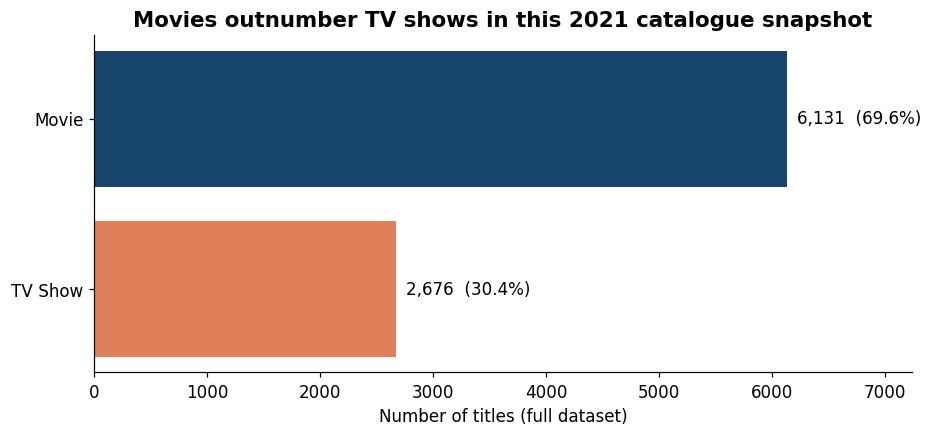

In [5]:
# Exploration 1: overall mix in the historical snapshot.
overall_types = df['type'].value_counts().reindex(['Movie', 'TV Show'])
fig, ax = plt.subplots(figsize=(8.7, 4.1))
bars = ax.barh(overall_types.index, overall_types.values, color=[BLUE, ORANGE])
ax.invert_yaxis()
ax.set_xlabel('Number of titles (full dataset)')
ax.set_title('Movies outnumber TV shows in this 2021 catalogue snapshot', weight='bold')
ax.set_xlim(0, overall_types.max() * 1.18)
for bar, count in zip(bars, overall_types):
    ax.text(count + 85, bar.get_y() + bar.get_height() / 2,
            f'{count:,}  ({100 * count / len(df):.1f}%)', va='center')
fig.tight_layout()
fig.savefig(FIGURES / 'exploration_01_overall_mix.png', bbox_inches='tight')
plt.show()

#### Observation

Movies dominate Netflix's catalogue, with 6,131 titles (69.6%), compared to 2,676 TV Shows (30.4%).

This shows that Netflix's catalogue was mainly movie-focused in this dataset. However, to understand whether Netflix has shifted towards TV Shows over time, we need to analyze how these percentages changed each year.

### Exploration 2: annual absolute numbers

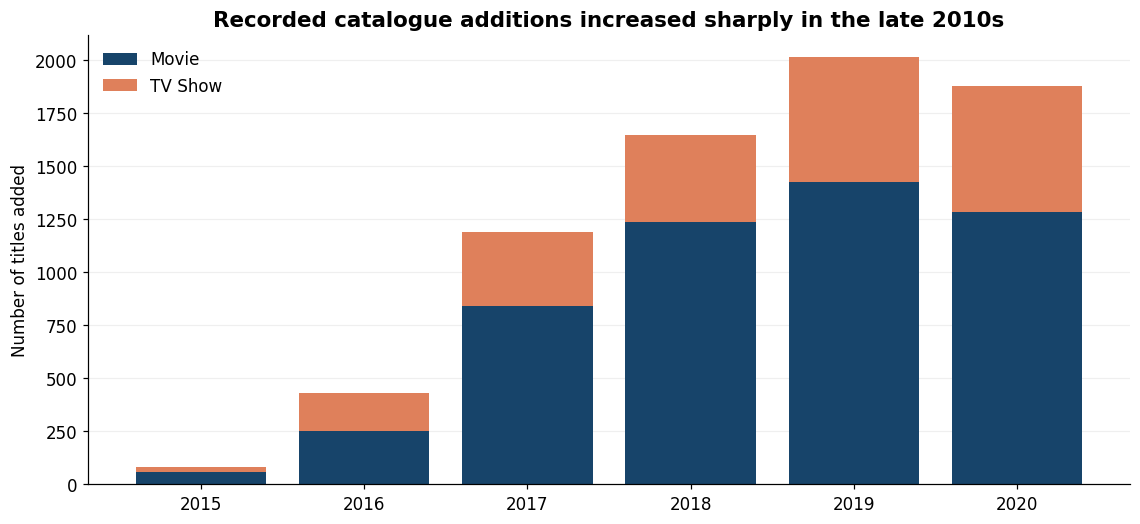

Important: a growing count does not prove a growing percentage.


In [6]:
# Exploration 2: annual absolute numbers. Counts are NOT percentages.
# Window 2015-2020: earlier years are too sparse to read, and 2021 is a
# partial year (additions end 25 September 2021), so it is excluded here.
annual = pd.crosstab(df['added_year'], df['type'])
annual = annual.reindex(range(2015, 2021), fill_value=0)
fig, ax = plt.subplots(figsize=(10.5, 4.9))
x = np.arange(len(annual))
ax.bar(x, annual['Movie'], label='Movie', color=BLUE)
ax.bar(x, annual['TV Show'], bottom=annual['Movie'], label='TV Show', color=ORANGE)
ax.set_xticks(x, annual.index)
ax.set_ylabel('Number of titles added')
ax.set_title('Recorded catalogue additions increased sharply in the late 2010s', weight='bold')
ax.legend(frameon=False)
ax.grid(axis='y', alpha=.2)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(FIGURES / 'exploration_02_additions_counts.png', bbox_inches='tight')
plt.show()
print('Important: a growing count does not prove a growing percentage.')

#### Observation

The number of Movies and TV Shows added to Netflix increased significantly between 2015 and 2019, with Movies making up the majority of additions. However, the number of titles added decreased in 2020.

This shows that Netflix's recorded catalogue additions grew rapidly, but we need to compare percentages to understand whether the balance between Movies and TV Shows changed over time.

### Exploration 3: top catalogue tags, counted once per title/tag.


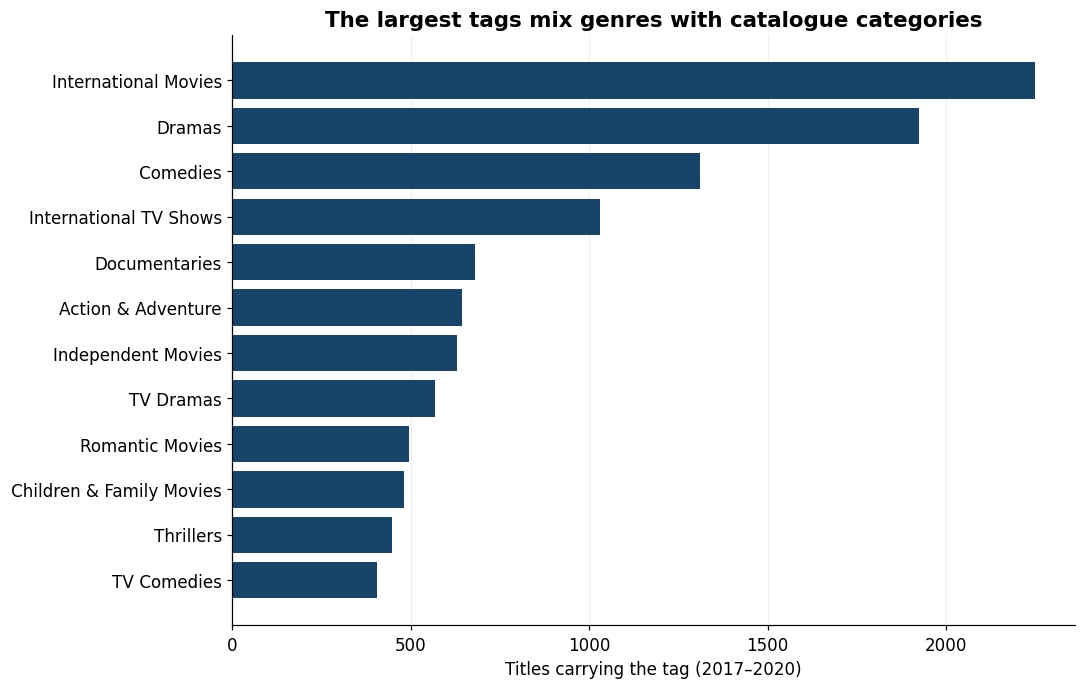

Tag counts overlap: a single movie can belong to several categories.


In [7]:
# Exploration 3: top catalogue tags, counted once per title/tag.
exploded_tags = analysis.explode('genre_tags')
top_tags = exploded_tags['genre_tags'].value_counts().head(12).sort_values()
fig, ax = plt.subplots(figsize=(10, 6.4))
ax.barh(top_tags.index, top_tags.values, color=BLUE)
ax.set_xlabel('Titles carrying the tag (2017–2020)')
ax.set_title('The largest tags mix genres with catalogue categories', weight='bold')
ax.grid(axis='x', alpha=.2)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(FIGURES / 'exploration_03_top_tags.png', bbox_inches='tight')
plt.show()
print('Tag counts overlap: a single movie can belong to several categories.')

#### Observation

International Movies is the most common category, followed by Dramas and Comedies. This shows that Netflix's catalogue contains a large amount of international content, with drama and comedy being particularly common genres.

However, some categories describe geographical origin rather than genres, and a single title can belong to multiple categories.

### Exploration 4: release year vs. added year measures an entirely different timeline.


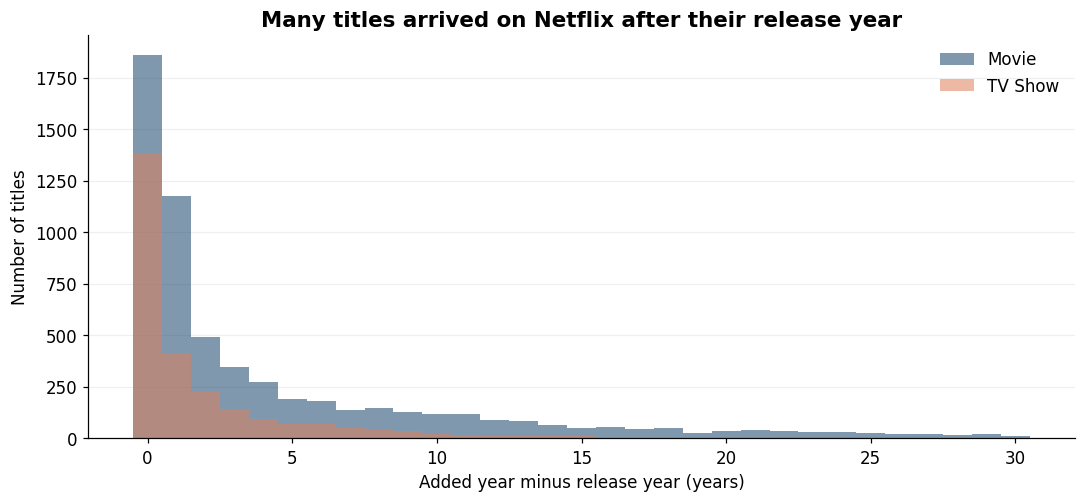

The graph limits gaps to 0–30 years for readability, not for the tests.


In [8]:
# Exploration 4: release year vs. added year measures an entirely different timeline.
valid_years = df[df['added_year'].notna()].copy()
valid_years['years_since_release'] = (
    valid_years['added_year'].astype(int) - valid_years['release_year']
)
release_gap = valid_years.loc[valid_years['years_since_release'].between(0, 30)]
fig, ax = plt.subplots(figsize=(10, 4.7))
for kind, color in [('Movie', BLUE), ('TV Show', ORANGE)]:
    subset = release_gap[release_gap['type'] == kind]
    ax.hist(subset['years_since_release'], bins=np.arange(-.5, 31.5, 1),
            alpha=.55, label=kind, color=color)
ax.set_xlabel('Added year minus release year (years)')
ax.set_ylabel('Number of titles')
ax.set_title('Many titles arrived on Netflix after their release year', weight='bold')
ax.legend(frameon=False)
ax.grid(axis='y', alpha=.2)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(FIGURES / 'exploration_04_release_gap.png', bbox_inches='tight')
plt.show()
print('The graph limits gaps to 0–30 years for readability, not for the tests.')

#### Observation

Many movies and TV shows were added to Netflix years after their original release. This shows that `release_year` and `date_added` represent different events.

Therefore, we should use `date_added` when analyzing how Netflix's catalogue has changed over time, rather than `release_year`.

### Exploration 5: production countries, counted once per title/country.


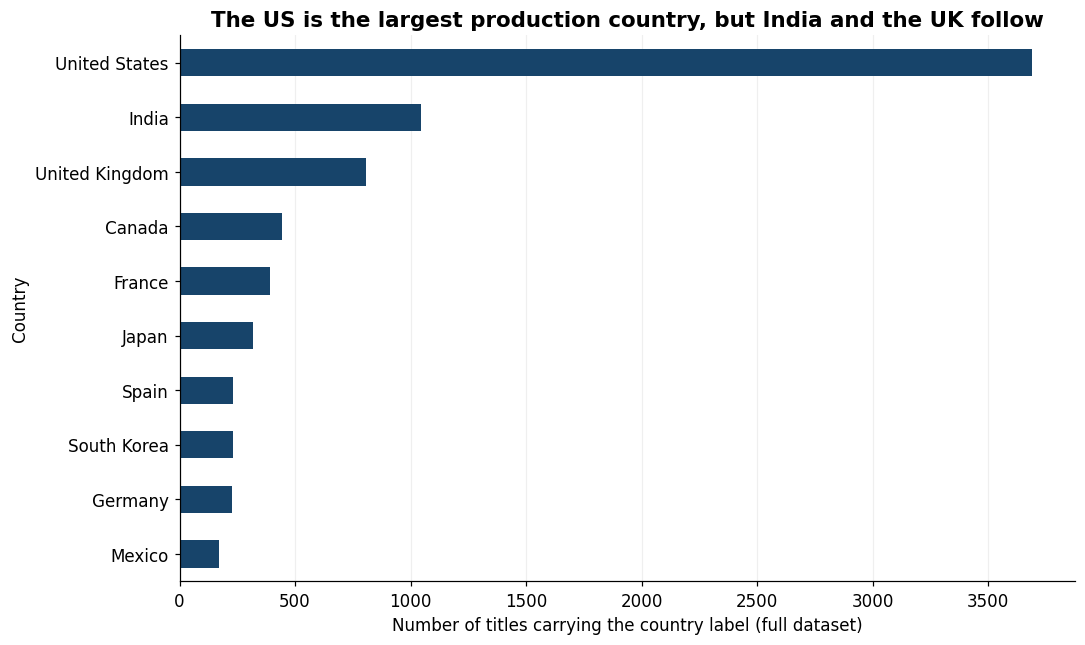

Co-productions are counted once per country, so country counts sum to more than 8,807.


In [9]:
# Exploration 5: production countries, counted once per title/country.
top_countries = (
    df["country_list"]
    .explode()
    .dropna()
    .value_counts()
    .head(10)
)

fig, ax = plt.subplots(figsize=(10, 6))
top_countries.sort_values().plot(kind="barh", color=BLUE, ax=ax)
ax.set_title("The US is the largest production country, but India and the UK follow", weight="bold")
ax.set_xlabel("Number of titles carrying the country label (full dataset)")
ax.set_ylabel("Country")
ax.grid(axis="x", alpha=.2)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(FIGURES / "exploration_05_top_countries.png", bbox_inches="tight")
plt.show()
print("Co-productions are counted once per country, so country counts sum to more than 8,807.")

#### Observation

The United States contributes the most titles to Netflix's catalogue (3,690), followed by India (1,046) and the United Kingdom (806). This shows that Netflix includes content from many countries, although the US has the largest representation.

### Exploration 6: US-linked vs non-US-only additions by year.


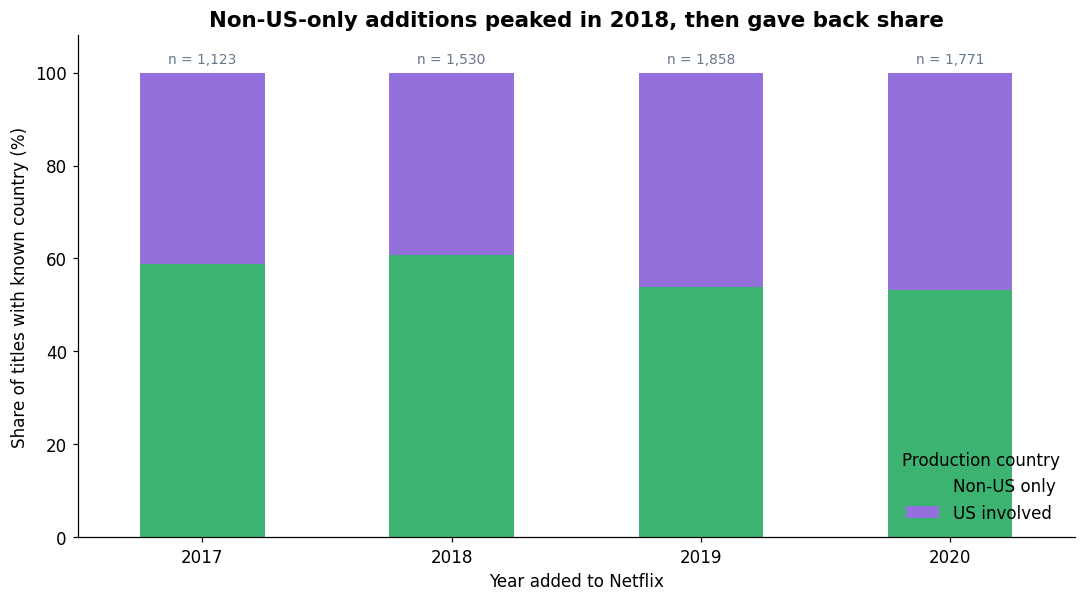

country_group,Non-US only,US involved
added_year,,
2017,58.9,41.1
2018,60.8,39.2
2019,53.9,46.1
2020,53.2,46.8


In [10]:
# Exploration 6: US-linked vs non-US-only additions by year.
# Only titles with a known country are used; the denominator is shown above each bar.
known = analysis[analysis["country_known"]].copy()
known["country_group"] = np.where(known["us_linked"], "US involved", "Non-US only")

country_counts = pd.crosstab(known["added_year"].astype(int), known["country_group"])
country_counts = country_counts.reindex(columns=["Non-US only", "US involved"], fill_value=0)

# Convert counts to percentages - rates, not raw counts.
country_percent = 100 * country_counts.div(country_counts.sum(axis=1), axis=0)

ax = country_percent.plot(
    kind="bar", stacked=True, figsize=(10, 5.6),
    color=["mediumseagreen", "mediumpurple"], rot=0,
)
for i, year in enumerate(country_percent.index):
    n = int(country_counts.loc[year].sum())
    ax.text(i, 102, f"n = {n:,}", ha="center", fontsize=9, color=GRAY)
ax.set_title("Non-US-only additions peaked in 2018, then gave back share", weight="bold")
ax.set_xlabel("Year added to Netflix")
ax.set_ylabel("Share of titles with known country (%)")
ax.set_ylim(0, 108)
ax.legend(title="Production country", frameon=False, loc="lower right")
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(FIGURES / "exploration_06_country_share.png", bbox_inches="tight")
plt.show()

display(country_percent.round(1))

#### Observation

Among titles with a known country, the share produced entirely outside the United States rose slightly from 58.9% in 2017 to 60.8% in 2018, then fell to 53.9% in 2019 and 53.2% in 2020. In other words, the non-US share peaked in 2018 and US-linked productions regained share afterwards.

Titles with missing country information are excluded (184 rows in 2017–2018, 266 in 2019–2020), and the yearly denominators are printed above the bars.

### Exploration 7: distribution of content ratings.


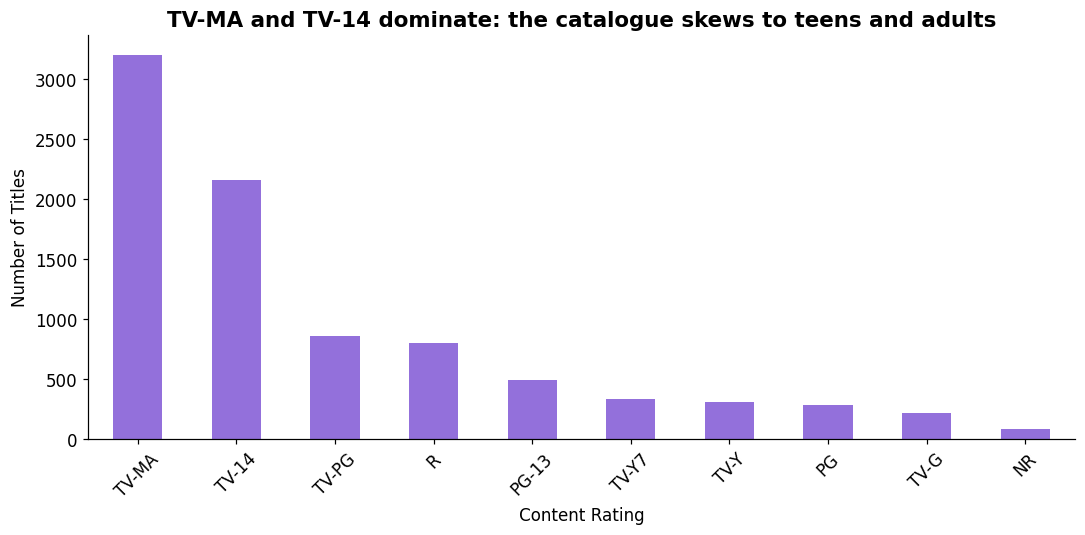

In [11]:
# Exploration 7: distribution of content ratings.
# Note: 3 rows carry a duration (e.g. "74 min") in the rating column instead of a
# rating - too rare to appear in this top 10, but documented in Section 6, Problem 2.
ratings = df["rating"].value_counts().head(10)

plt.figure(figsize=(10, 5))

ratings.plot(
    kind="bar",
    color="mediumpurple"
)

plt.title("TV-MA and TV-14 dominate: the catalogue skews to teens and adults", weight="bold")
plt.xlabel("Content Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Observation

TV-MA is the most common content rating, followed by TV-14. This suggests that a large part of Netflix's catalogue is classified for mature or teenage audiences.

### Exploration 8: average movie duration by year added.


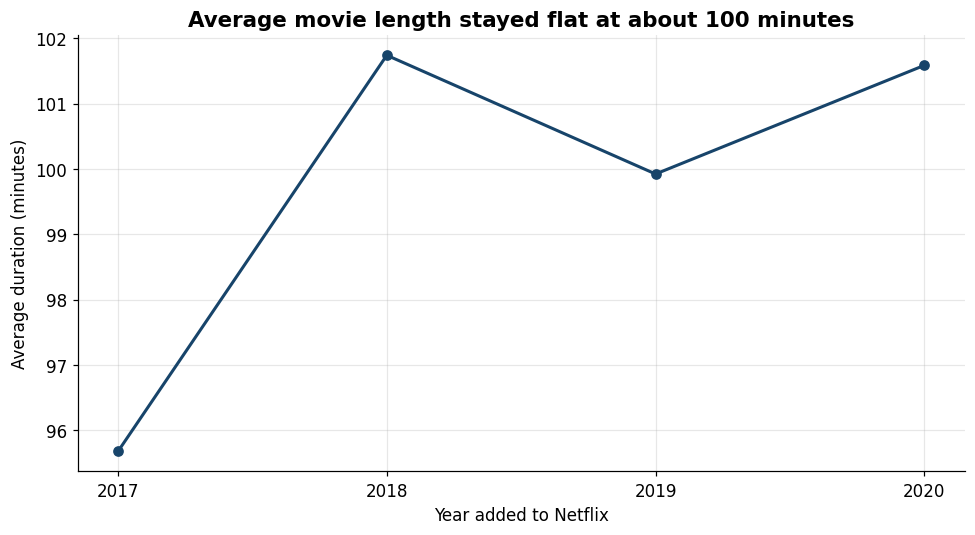

added_year
2017     95.7
2018    101.7
2019     99.9
2020    101.6
Name: duration_minutes, dtype: float64


In [12]:
# Exploration 8: average movie duration by year added.
# Movies only: "duration" means minutes for movies but seasons for TV shows,
# so the two types can never be averaged together.
movies = analysis[analysis["type"] == "Movie"].copy()
movies["duration_minutes"] = pd.to_numeric(
    movies["duration"].str.extract(r"(\d+)")[0],
    errors="coerce",
)

avg_duration = movies.groupby(movies["added_year"].astype(int))["duration_minutes"].mean()

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(avg_duration.index, avg_duration.values, marker="o", color=BLUE, linewidth=2)
ax.set_title("Average movie length stayed flat at about 100 minutes", weight="bold")
ax.set_xlabel("Year added to Netflix")
ax.set_ylabel("Average duration (minutes)")
ax.set_xticks(avg_duration.index)
ax.grid(alpha=.3)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(FIGURES / "exploration_08_movie_duration.png", bbox_inches="tight")
plt.show()
print(avg_duration.round(1))

#### Observation

Average movie duration was essentially flat across the window — 95.7 minutes in 2017 and 99.9–101.7 minutes in 2018–2020. Running time is not part of Netflix's change story.

This chart also shows why cleaning kept the two types apart: `duration` stores minutes for movies but season counts for TV shows, so a single average across the catalogue would be meaningless.

## 5. Testing the hypotheses — each marked survived or rejected

Each hypothesis from Section 2 is now tested with the two pre-declared windows (**2017–2018** vs **2019–2020**). Percentages are used rather than raw counts, because the later window contains more titles overall (3,895 vs 2,837) — comparing counts would confuse catalogue growth with a change in mix. The denominator is stated under every figure.

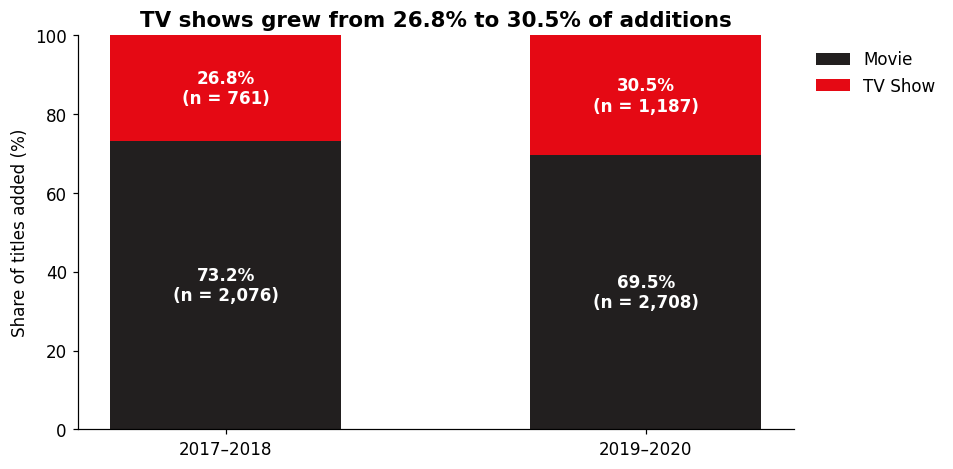

TV share of additions by calendar year (%):
added_year
2016    41.0
2017    29.4
2018    25.0
2019    29.4
2020    31.7
2021    33.7

type       Movie  TV Show  total
period                          
2017–2018   2076      761   2837
2019–2020   2708     1187   3895


In [22]:
# H1 test: TV share of additions, by period. Rates, with denominators.
h1_counts = pd.crosstab(analysis["period"], analysis["type"]).reindex(PERIODS)
h1_share = 100 * h1_counts.div(h1_counts.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(8.8, 4.4))
bottoms = np.zeros(len(PERIODS))
for kind, color in [("Movie", "#221F1F"), ("TV Show", "#E50914")]:
    values = h1_share[kind].values
    bars = ax.bar(PERIODS, values, bottom=bottoms, label=kind, color=color, width=.55)
    for bar, value, count in zip(bars, values, h1_counts[kind]):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_y() + value / 2,
                f"{value:.1f}%\n(n = {count:,})", ha="center", va="center",
                color="white", fontsize=11, weight="bold")
    bottoms += values
ax.set_ylim(0, 100)
ax.set_ylabel("Share of titles added (%)")
ax.set_title("TV shows grew from 26.8% to 30.5% of additions", weight="bold")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
fig.savefig(FIGURES / "h1_tv_share_by_period.png", bbox_inches="tight")
plt.show()

yearly_tv = (100 * pd.crosstab(df["added_year"], df["type"])
             .pipe(lambda t: t["TV Show"] / t.sum(axis=1))).dropna().round(1)
print("TV share of additions by calendar year (%):")
print(yearly_tv.loc[2016:2021].to_string())
print()
print(h1_counts.assign(total=h1_counts.sum(axis=1)).to_string())

### H1 — Survived, but the increase is modest

TV shows were **26.8% of additions in 2017–2018 and 30.5% in 2019–2020** (+3.7 percentage points; denominators n = 2,837 and n = 3,895). The yearly figures — 29.4%, 25.0%, 29.4%, 31.7%, and 33.7% in partial-2021 — show the direction is real but not steady: 2018 dipped below 2017 before the share climbed again.

**Verdict: survived**, with the caveat that this is a gradual drift in mix, not a sharp pivot to TV.

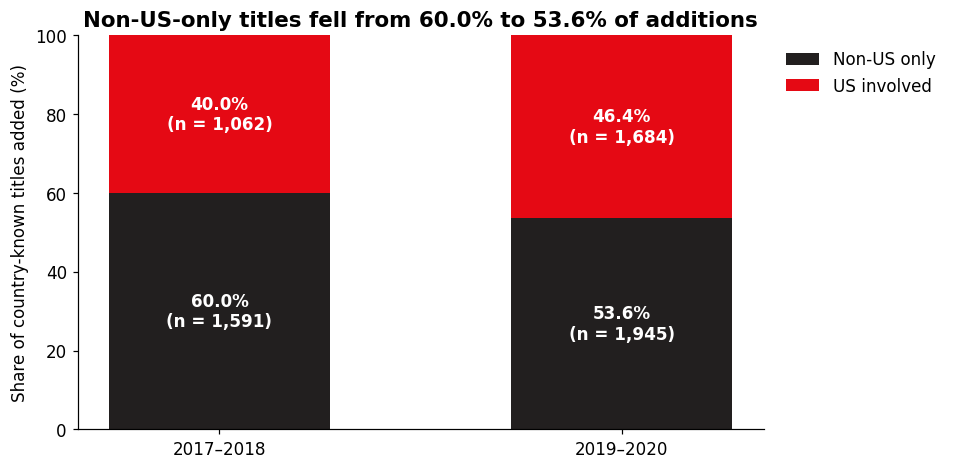

Non-US-only share of additions by calendar year (%):
added_year
2017    58.9
2018    60.8
2019    53.9
2020    53.2

country_group  Non-US only  US involved  total
period                                        
2017–2018             1591         1062   2653
2019–2020             1945         1684   3629
Excluded for missing country: {'2017–2018': 184, '2019–2020': 266}


In [19]:
# H2 test: share of additions with no US involvement, by period.
# Titles with missing country are excluded; denominators stated below.
known = analysis[analysis["country_known"]].copy()
known["country_group"] = np.where(known["us_linked"], "US involved", "Non-US only")

h2_counts = pd.crosstab(known["period"], known["country_group"]).reindex(PERIODS)
h2_counts = h2_counts[["Non-US only", "US involved"]]
h2_share = 100 * h2_counts.div(h2_counts.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(8.8, 4.4))
bottoms = np.zeros(len(PERIODS))
for group, color in [("Non-US only", "#221F1F"), ("US involved", "#E50914")]:
    values = h2_share[group].values
    bars = ax.bar(PERIODS, values, bottom=bottoms, label=group, color=color, width=.55)
    for bar, value, count in zip(bars, values, h2_counts[group]):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_y() + value / 2,
                f"{value:.1f}%\n(n = {count:,})", ha="center", va="center",
                color="white", fontsize=11, weight="bold")
    bottoms += values
ax.set_ylim(0, 100)
ax.set_ylabel("Share of country-known titles added (%)")
ax.set_title("Non-US-only titles fell from 60.0% to 53.6% of additions", weight="bold")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
fig.savefig(FIGURES / "h2_country_share_by_period.png", bbox_inches="tight")
plt.show()

yearly_non_us = (100 * pd.crosstab(known["added_year"], known["non_us_only"])
                 .pipe(lambda t: t[True] / t.sum(axis=1))).round(1)
print("Non-US-only share of additions by calendar year (%):")
print(yearly_non_us.to_string())
print()
print(h2_counts.assign(total=h2_counts.sum(axis=1)).to_string())
print("Excluded for missing country:",
      analysis.groupby("period")["country_known"].apply(lambda s: int((~s).sum())).to_dict())

### H2 — Rejected

We predicted the share of titles produced entirely outside the US would rise. **The opposite happened**: among titles with a known country, the non-US-only share fell from **60.0% in 2017–2018 to 53.6% in 2019–2020** (−6.4 percentage points; denominators n = 2,653 and n = 3,629 after excluding 184 and 266 titles with missing country).

The yearly figures (58.9% → 60.8% → 53.9% → 53.2%) locate the break precisely: the non-US share peaked in 2018 and dropped between 2018 and 2019. A rejected hypothesis is still a result — in this data, Netflix's additions became *more* US-linked after 2018, not less.

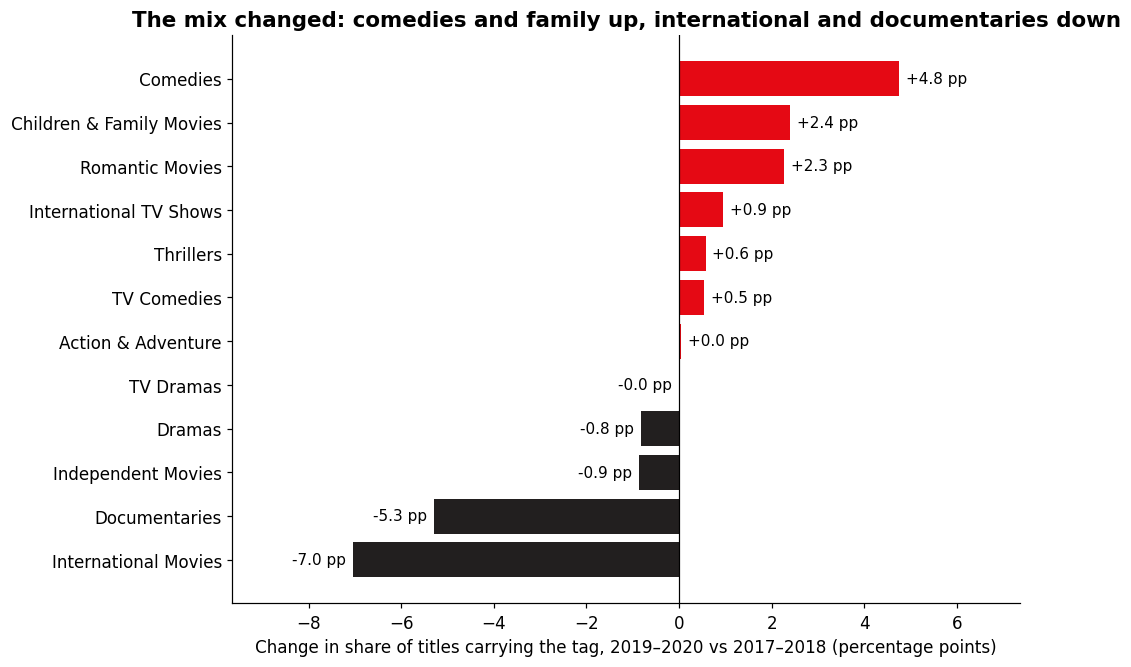

period                    2017–2018  2019–2020  change_pp
genre_tags                                               
International Movies           37.5       30.4       -7.0
Dramas                         29.0       28.2       -0.8
Comedies                       16.7       21.5        4.8
International TV Shows         14.8       15.7        0.9
Documentaries                  13.1        7.9       -5.3
Action & Adventure              9.5        9.6        0.0
Independent Movies              9.8        9.0       -0.9
TV Dramas                       8.4        8.4       -0.0
Romantic Movies                 6.0        8.3        2.3
Children & Family Movies        5.7        8.1        2.4
Thrillers                       6.3        6.9        0.6
TV Comedies                     5.7        6.2        0.5


In [20]:
# H3 test: change in tag prevalence between the two periods.
# Share of titles in each period carrying each tag (tags overlap, so shares do not sum to 100).
tags = analysis.explode("genre_tags")
tag_counts = pd.crosstab(tags["genre_tags"], tags["period"]).reindex(columns=PERIODS, fill_value=0)
period_sizes = analysis.groupby("period").size()
tag_share = 100 * tag_counts.div(period_sizes, axis=1)

top12 = tag_counts.sum(axis=1).sort_values(ascending=False).head(12).index
shift = (tag_share.loc[top12, "2019–2020"] - tag_share.loc[top12, "2017–2018"]).sort_values()

fig, ax = plt.subplots(figsize=(9.5, 6.2))
ax.barh(shift.index, shift.values,
        color=["#E50914" if v > 0 else "#221F1F" for v in shift.values])
ax.axvline(0, color="black", lw=.8)
for y, v in enumerate(shift.values):
    ax.text(v + (.15 if v > 0 else -.15), y, f"{v:+.1f} pp",
            va="center", ha="left" if v > 0 else "right", fontsize=10)
ax.set_xlim(shift.min() - 2.6, shift.max() + 2.6)
ax.set_xlabel("Change in share of titles carrying the tag, 2019–2020 vs 2017–2018 (percentage points)")
ax.set_title("The mix changed: comedies and family up, international and documentaries down",
             weight="bold")
fig.tight_layout()
fig.savefig(FIGURES / "h3_tag_shift.png", bbox_inches="tight")
plt.show()

print(tag_share.loc[top12].round(1).assign(change_pp=shift.round(1)).to_string())

### H3 — Survived

The content mix changed materially between the two windows:

| Tag | 2017–2018 | 2019–2020 | Change |
|---|---|---|---|
| International Movies | 37.5% | 30.4% | **−7.0 pp** |
| Documentaries | 13.1% | 7.9% | **−5.3 pp** |
| Comedies | 16.7% | 21.5% | **+4.8 pp** |
| Children & Family Movies | 5.7% | 8.1% | **+2.4 pp** |
| Romantic Movies | 6.0% | 8.3% | **+2.3 pp** |
| Dramas | 29.0% | 28.2% | −0.8 pp |

Core genres like Dramas and Action & Adventure barely moved, so the change is concentrated: **away from the 2017–2018 international-movie and documentary licensing wave, toward mainstream comedy and family content** — consistent with H2's post-2018 tilt back toward US-linked productions.

One caveat kept from exploration: two of the biggest movers (*International Movies*, *International TV Shows*) are geographic labels, not genres. Netflix's `listed_in` tags mix origin with genre, which limits how cleanly “genre change” can be measured with this column alone.

## 6. Three things wrong with this data

Each problem is proven with code. These are traps: ways of reading this dataset that produce a confident, wrong answer.

Titles released before Netflix existed (pre-1997): 412 (4.7% of the catalogue)
Titles released before Netflix streaming launched (pre-2007): 959
Oldest release year in the data: 1925


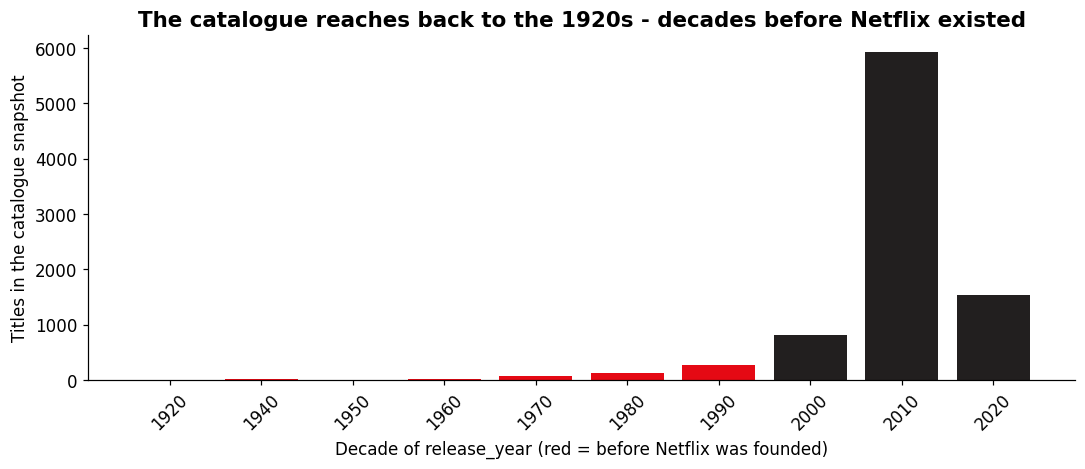

In [21]:
# Problem 1: release_year is not a Netflix timeline.
NETFLIX_FOUNDED = 1997      # company founded
STREAMING_LAUNCH = 2007     # streaming service launched
pre_company = int((df["release_year"] < NETFLIX_FOUNDED).sum())
pre_streaming = int((df["release_year"] < STREAMING_LAUNCH).sum())
print(f"Titles released before Netflix existed (pre-1997): {pre_company:,} "
      f"({100 * pre_company / len(df):.1f}% of the catalogue)")
print(f"Titles released before Netflix streaming launched (pre-2007): {pre_streaming:,}")
print(f"Oldest release year in the data: {int(df['release_year'].min())}")

decade_counts = (df["release_year"] // 10 * 10).astype(int).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(10, 4.4))
colors = ["#E50914" if d < NETFLIX_FOUNDED else "#221F1F" for d in decade_counts.index]
ax.bar(decade_counts.index.astype(str), decade_counts.values, color=colors)
ax.set_xlabel("Decade of release_year (red = before Netflix was founded)")
ax.set_ylabel("Titles in the catalogue snapshot")
ax.set_title("The catalogue reaches back to the 1920s - decades before Netflix existed",
             weight="bold")
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(FIGURES / "problem_1_release_decades.png", bbox_inches="tight")
plt.show()

**Problem 1 — `release_year` says when a title was made, not when Netflix had it.** 412 titles (4.7% of the catalogue) carry a release year before Netflix was founded in 1997, 959 predate the 2007 streaming launch, and the oldest is from 1925. Anyone who groups this dataset by `release_year` to show “Netflix's growth” plots Netflix content in the 1930s — a confident, wrong chart, and a trap published analyses of this exact dataset have fallen into. It matters directly for our question: the history of the *company* exists only in `date_added`, and the yearly distribution of “Netflix movies” is placed in the wrong years entirely if licensed old films are counted at their release year instead of the year they entered the catalogue. That is why every time comparison in this notebook uses `date_added`.

In [17]:
# Problem 2: the rating column does not always contain a rating.
duration_in_rating = df[df["rating"].str.contains(r"\d+\s*min", na=False)]
print(f"Rows where the rating field holds a running time: {len(duration_in_rating)}")
display(duration_in_rating[["show_id", "title", "type", "rating", "duration"]])

Rows where the rating field holds a running time: 3


,show_id,title,type,rating,duration
5541,s5542,Louis C.K. 2017,Movie,74 min,NaN
5794,s5795,Louis C.K.: Hilarious,Movie,84 min,NaN
5813,s5814,Louis C.K.: Live at the Comedy Store,Movie,66 min,NaN


**Problem 2 — a column that says one thing and means another.** Three records (all stand-up specials) hold a running time (“74 min”, “84 min”, “66 min”) in the `rating` column, with `duration` left empty — the values were shifted one column when the data was collected. Any rating distribution or duration average computed without checking first silently absorbs these rows into the wrong column. The count is small, but the pattern is the point: a column's name is not a guarantee of its contents.

A related quirk we handled in cleaning: `duration` stores **minutes for movies but season counts for TV shows**, so it can never be averaged or compared across the two types.

,missing,total,pct_missing
type,,,
Movie,188,6131,3.1
TV Show,2446,2676,91.4


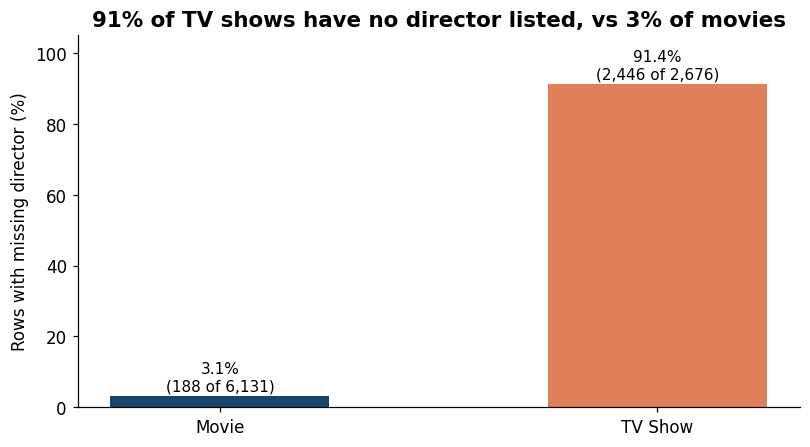

In [18]:
# Problem 3: missing directors are NOT missing at random.
director_missing = (df.assign(dir_missing=df["director"].isna())
                    .groupby("type")["dir_missing"]
                    .agg(["sum", "count", "mean"]))
director_missing.columns = ["missing", "total", "pct_missing"]
director_missing["pct_missing"] = (100 * director_missing["pct_missing"]).round(1)
display(director_missing)

fig, ax = plt.subplots(figsize=(7.5, 4.2))
bars = ax.bar(director_missing.index, director_missing["pct_missing"],
              color=[BLUE, ORANGE], width=.5)
for bar, (kind, row) in zip(bars, director_missing.iterrows()):
    ax.text(bar.get_x() + bar.get_width() / 2, row["pct_missing"] + 1.5,
            f"{row['pct_missing']:.1f}%\n({int(row['missing']):,} of {int(row['total']):,})",
            ha="center", fontsize=10)
ax.set_ylim(0, 105)
ax.set_ylabel("Rows with missing director (%)")
ax.set_title("91% of TV shows have no director listed, vs 3% of movies", weight="bold")
fig.tight_layout()
fig.savefig(FIGURES / "problem_3_director_missing.png", bbox_inches="tight")
plt.show()

**Problem 3 — missing values that are not missing at random.** 91.4% of TV shows have no director listed, versus 3.1% of movies. The missingness is structural: series rarely credit a single director, so `director` is effectively a movie-only field. Any analysis conditioned on it — “which directors dominate Netflix”, say — would be a movie-only analysis while appearing to cover the whole catalogue. This is why Section 3 refuses to impute `director` or `cast`, and why none of our hypotheses depend on them.

## 7. Conclusion and limitations

### The answer

In this snapshot, Netflix in 2019–2020 was still a movie-dominated catalogue (69.6% of all titles), but the balance of what it *added* had shifted. The TV share of additions climbed from 26.8% to 30.5% and kept climbing in 2021 (33.7%); the post-2018 additions tilted back toward US-linked productions (non-US-only share fell from 60.0% to 53.6%); and the fastest-growing categories were mainstream comedies and family films while the international-movie and documentary licensing wave receded. **The turning point sits between 2018 and 2019**: additions peaked in 2019 (2,016 titles), and every mix shift we measured changes direction around that year.

So, in one sentence: ***“Around 2018–2019 Netflix's catalogue additions peaked and pivoted — away from licensed international movies, toward TV shows and mainstream, largely US-linked, comedy and family content.”***

### Limitations — what would change this answer

- **We see additions, not the catalogue.** The file records when titles were *added*, not when they left. We cannot reconstruct what subscribers actually saw in any given year — a title added in 2017 may have been gone by 2019. If removals were concentrated among international titles, our “less international after 2018” finding would be understated, or wrong.
- **“Now” stops on 25 September 2021.** The dataset ends there, so nothing here speaks to the ad-tier, password-sharing, or games era. Our answer describes Netflix at the start of the decade, not Netflix today — and 2021 itself is a partial year, which is why no full-year comparison uses it.
- **Country and genre labels are imperfect.** Country is missing for 450 of the 6,732 comparison rows, and `listed_in` mixes geography with genre, so H2 and H3 partly measure Netflix's *labelling* habits, not just production reality.
- **We cannot identify Netflix Originals.** Release year equalling added year is only a rough proxy for first-run content, so we cannot cleanly separate commissioned originals from licensed catalogue — the distinction that most defines what kind of company Netflix is.
- **No viewing, revenue, or spending data.** What Netflix adds and what people actually watch can be very different things; this dataset cannot see the difference. Viewing-hours data, removal dates, and post-2021 additions are the three things most likely to change our answer.

*What this data could not tell you (poster line): what subscribers actually watched, what was removed from the catalogue, and anything after September 2021.*